# Practical 5: Regularisation with Ridge and Lasso Regression

**Subject:** Machine Learning  |  **Type:** Supervised learning, regularised regression

## Aim
Apply **regularisation techniques such as Ridge and Lasso regression** on a suitable multivariate open-access dataset and observe their influence on **model overfitting and multicollinearity**.

## Dataset
**Diabetes dataset** (scikit-learn, 442 patients, 10 features). Several features (`s1`, `s2`, `s3`, `s4`, `s5`) are strongly correlated with each other, so it is ideal for studying multicollinearity. For the overfitting demonstration we add polynomial features (65 features) and use only a small training set.

## Steps
1. Load, split, scale
2. Part A: multicollinearity. Compare OLS, Ridge, Lasso coefficients and their stability
3. Coefficient paths versus alpha
4. Choose alpha with cross-validation
5. Part B: overfitting. Many features, few samples
6. Validation curve (error versus alpha)

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
np.random.seed(42)

## Step 1: Load, split and scale

In [2]:
data = load_diabetes()
X, y, names = data.data, data.target, list(data.feature_names)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (309, 10) | Test: (133, 10)


**Why scale?** The penalty $\alpha\sum\beta_j^2$ (or $\alpha\sum|\beta_j|$) punishes coefficient size, which depends on the feature's scale. Standardising makes the penalty fair across features.

## Part A: Multicollinearity

First, how correlated are the features?

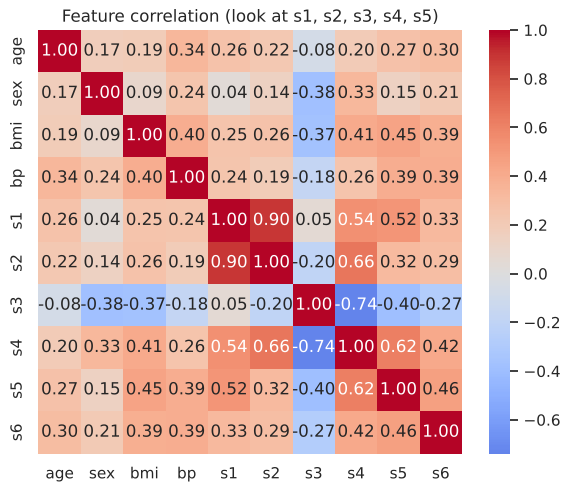

s1     53.8
s2     34.7
s3     13.8
s5     10.1
s4      9.3
bmi     1.6
s6      1.5
bp      1.4
sex     1.2
age     1.2
Name: VIF, dtype: float64


In [3]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(pd.DataFrame(X, columns=names).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Feature correlation (look at s1, s2, s3, s4, s5)"); plt.show()
corr = np.corrcoef(X_train_s.T)
vif = pd.Series(np.diag(np.linalg.inv(corr)), index=names, name="VIF").sort_values(ascending=False)
print(vif.round(1))

**How to read this:** `s1` and `s2` are correlated at about 0.9, and `s1`, `s2`, `s4`, `s5` form a correlated group. Their VIF values are high (above 5 or 10), which means plain linear regression cannot separate their individual effects.

### Fit OLS, Ridge and Lasso and compare

In [4]:
models = {
    "Linear (OLS)": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10),
    "Lasso (alpha=2)": Lasso(alpha=2, max_iter=20000),
}
coefs, rows = {}, []
for n, m in models.items():
    m.fit(X_train_s, y_train)
    pred_te = m.predict(X_test_s)
    rows.append({"Model": n,
                 "Train R2": r2_score(y_train, m.predict(X_train_s)),
                 "Test R2": r2_score(y_test, pred_te),
                 "Test MSE": mean_squared_error(y_test, pred_te),
                 "Non-zero coefs": int(np.sum(np.abs(m.coef_) > 1e-8))})
    coefs[n] = m.coef_

pd.DataFrame(rows).round(3)

,Model,Train R2,Test R2,Test MSE,Non-zero coefs
0,Linear (OLS),0.524,0.477,2821.751,10
1,Ridge (alpha=10),0.521,0.478,2817.491,10
2,Lasso (alpha=2),0.514,0.486,2774.740,7


     Linear (OLS)  Ridge (alpha=10)  Lasso (alpha=2)
age          1.35              1.67             0.00
sex        -12.45            -11.76            -8.41
bmi         26.21             26.19            26.81
bp          18.61             17.83            16.35
s1         -43.26            -12.26            -2.99
s2          24.26              0.66            -0.00
s3           5.74             -7.76           -13.08
s4          13.96              9.19             0.00
s5          31.58             19.35            17.96
s6           1.98              2.70             1.29


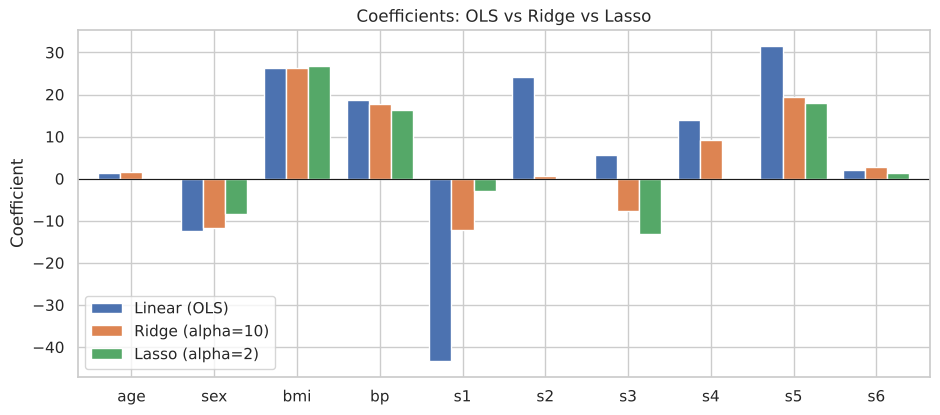

In [5]:
coef_df = pd.DataFrame(coefs, index=names).round(2)
print(coef_df)
coef_df.plot(kind="bar", figsize=(11, 4.5), width=0.8)
plt.axhline(0, color="k", lw=0.8); plt.ylabel("Coefficient"); plt.title("Coefficients: OLS vs Ridge vs Lasso")
plt.xticks(rotation=0); plt.show()

**How to read this bar chart:** each group is one feature and the colours are the models.
- **OLS** has the largest coefficients, and for the correlated features (`s1`, `s2`) they are large and opposite in sign. This is the signature of multicollinearity: the model splits the effect between near-duplicate features unstably.
- **Ridge** shrinks all coefficients toward zero, so the correlated features share the weight. None is exactly zero.
- **Lasso** sets some coefficients to **exactly zero**, so it drops those features (automatic feature selection).

### Do the coefficients become more stable? (bootstrap check)

We refit each model on 200 resampled training sets and look at how much the coefficients of `s1` and `s2` vary. Smaller spread means a more stable model.

                  OLS  Ridge  Lasso
Std of s1 coef  20.72   5.01   4.26
Std of s2 coef  15.82   4.45   2.45


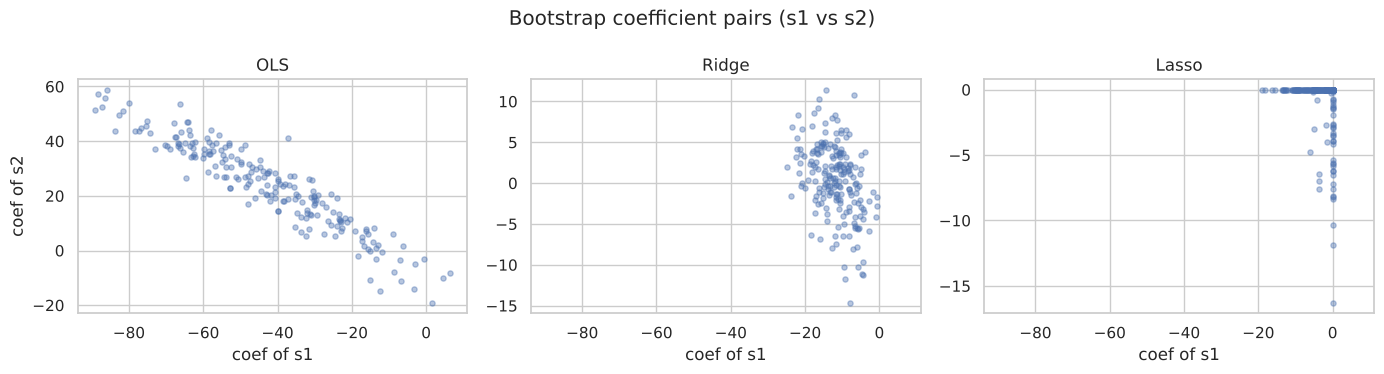

In [6]:
rng = np.random.default_rng(1)
B = 200
store = {n: [] for n in ["OLS", "Ridge", "Lasso"]}
for _ in range(B):
    idx = rng.integers(0, len(X_train_s), len(X_train_s))
    Xb, yb = X_train_s[idx], y_train[idx]
    store["OLS"].append(LinearRegression().fit(Xb, yb).coef_)
    store["Ridge"].append(Ridge(alpha=10).fit(Xb, yb).coef_)
    store["Lasso"].append(Lasso(alpha=2, max_iter=20000).fit(Xb, yb).coef_)

i1, i2 = names.index("s1"), names.index("s2")
stab = pd.DataFrame({n: [np.std(np.array(v)[:, i1]), np.std(np.array(v)[:, i2])] for n, v in store.items()},
                    index=["Std of s1 coef", "Std of s2 coef"]).round(2)
print(stab)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for a, (n, v) in zip(ax, store.items()):
    v = np.array(v)
    a.scatter(v[:, i1], v[:, i2], alpha=0.4, s=14)
    a.set_title(n); a.set_xlabel("coef of s1")
ax[0].set_ylabel("coef of s2")
plt.suptitle("Bootstrap coefficient pairs (s1 vs s2)"); plt.tight_layout(); plt.show()

**How to read this:** each dot is the (s1, s2) coefficient pair from one bootstrap sample. For OLS the dots are spread over a wide, tilted ellipse: the coefficients change a lot from sample to sample and trade off against each other (when one goes up the other goes down). For Ridge the cloud is much tighter and closer to zero, which means regularisation stabilised the estimates. This is the direct effect of Ridge on multicollinearity.

## Step 3: Coefficient paths (how coefficients change with alpha)

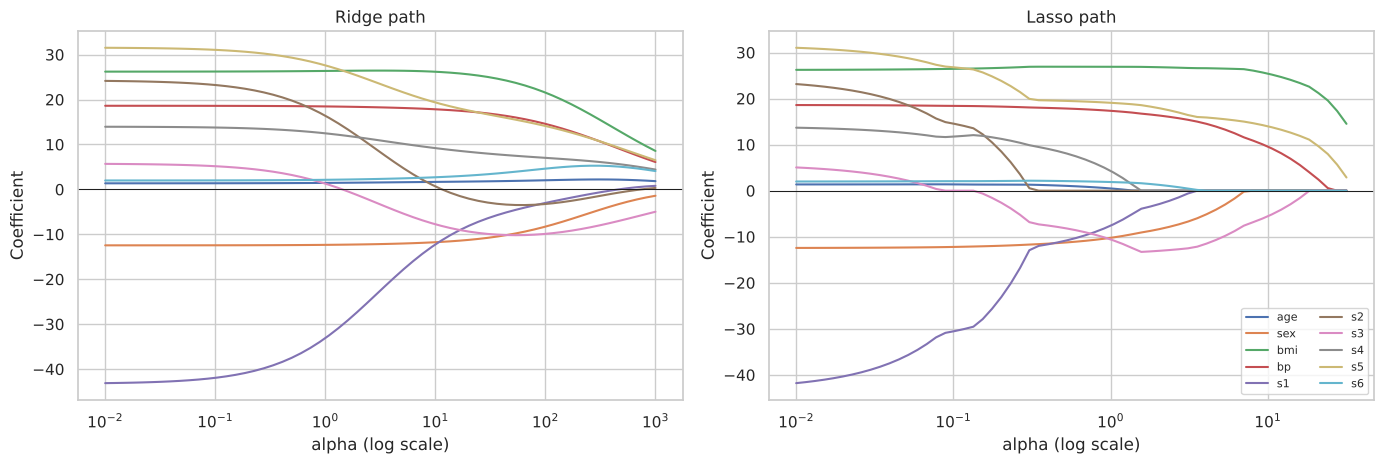

In [7]:
alphas = np.logspace(-2, 3, 60)
ridge_path = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in alphas])
lasso_alphas = np.logspace(-2, 1.5, 60)
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(X_train_s, y_train).coef_ for a in lasso_alphas])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for j, nm in enumerate(names):
    ax[0].plot(alphas, ridge_path[:, j], label=nm)
    ax[1].plot(lasso_alphas, lasso_path[:, j], label=nm)
for a, t in zip(ax, ["Ridge path", "Lasso path"]):
    a.set_xscale("log"); a.axhline(0, color="k", lw=0.7)
    a.set_xlabel("alpha (log scale)"); a.set_ylabel("Coefficient"); a.set_title(t)
ax[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

**How to read these graphs**
- **X-axis:** regularisation strength alpha (log scale). The left side is almost no penalty (coefficients ≈ OLS values); the right side is a very strong penalty.
- **Ridge path:** all coefficients shrink **smoothly** toward zero as alpha grows but never reach exactly zero. Correlated features (such as `s1` and `s2`) first move strongly and then converge.
- **Lasso path:** coefficients drop to **exactly zero one by one** and stay there. The last features to be removed are the most important ones (here `s5`, `bmi`, `bp`).

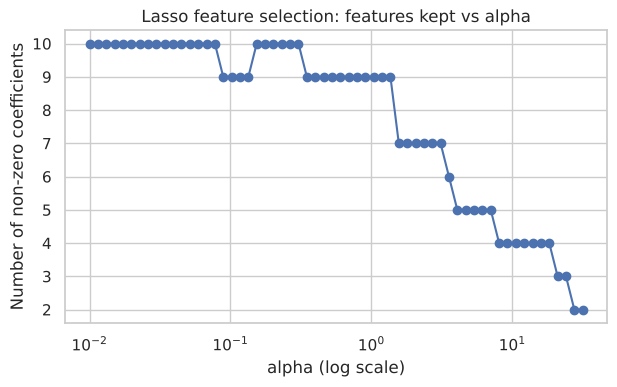

In [8]:
nz = (np.abs(lasso_path) > 1e-8).sum(axis=1)
plt.figure(figsize=(7, 3.8))
plt.plot(lasso_alphas, nz, "o-")
plt.xscale("log"); plt.xlabel("alpha (log scale)"); plt.ylabel("Number of non-zero coefficients")
plt.title("Lasso feature selection: features kept vs alpha"); plt.show()

**How to read this:** as alpha increases, Lasso keeps fewer and fewer features, ending with zero features (a model that predicts only the mean).

## Step 4: Choose alpha with cross-validation

In [9]:
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5).fit(X_train_s, y_train)
lasso_cv = LassoCV(alphas=np.logspace(-3, 1, 100), cv=5, max_iter=50000).fit(X_train_s, y_train)
print("Best Ridge alpha:", round(ridge_cv.alpha_, 3), "| Test R2:", round(ridge_cv.score(X_test_s, y_test), 3))
print("Best Lasso alpha:", round(lasso_cv.alpha_, 3), "| Test R2:", round(lasso_cv.score(X_test_s, y_test), 3))
print("OLS Test R2     :", round(LinearRegression().fit(X_train_s, y_train).score(X_test_s, y_test), 3))
print("Features kept by tuned Lasso:", [n for n, c_ in zip(names, lasso_cv.coef_) if abs(c_) > 1e-8])

Best Ridge alpha: 1.233 | Test R2: 0.478
Best Lasso alpha: 0.115 | Test R2: 0.478
OLS Test R2     : 0.477
Features kept by tuned Lasso: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']


Cross-validation picks the alpha with the lowest validation error. Notice that on this dataset the test R² of OLS, Ridge and Lasso are close: with only 10 features and 300 training samples, overfitting is mild. The benefit of regularisation is much clearer in Part B.

## Part B: Overfitting (many features, few samples)

We expand the 10 features into **65 polynomial features** (degree 2, with interactions) and train on only **80 samples**. With so many features for so few samples, plain OLS overfits strongly.

In [10]:
Xs_tr, _, ys_tr, _ = train_test_split(X_train, y_train, train_size=80, random_state=0)

def make(reg):
    return make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), reg)

models_b = {
    "Linear (OLS)": make(LinearRegression()),
    "Ridge (alpha=100)": make(Ridge(alpha=100)),
    "Lasso (alpha=3)": make(Lasso(alpha=3, max_iter=100000)),
}
rows = []
for n, m in models_b.items():
    m.fit(Xs_tr, ys_tr)
    rows.append({"Model": n,
                 "Train R2": r2_score(ys_tr, m.predict(Xs_tr)),
                 "Test R2": r2_score(y_test, m.predict(X_test)),
                 "Test MSE": mean_squared_error(y_test, m.predict(X_test))})
res_b = pd.DataFrame(rows).round(3)
res_b["Gap (train - test R2)"] = (res_b["Train R2"] - res_b["Test R2"]).round(3)
res_b

,Model,Train R2,Test R2,Test MSE,Gap (train - test R2)
0,Linear (OLS),0.944,-2.837,20711.079,3.781
1,Ridge (alpha=100),0.737,0.339,3566.688,0.398
2,Lasso (alpha=3),0.801,0.269,3947.308,0.532


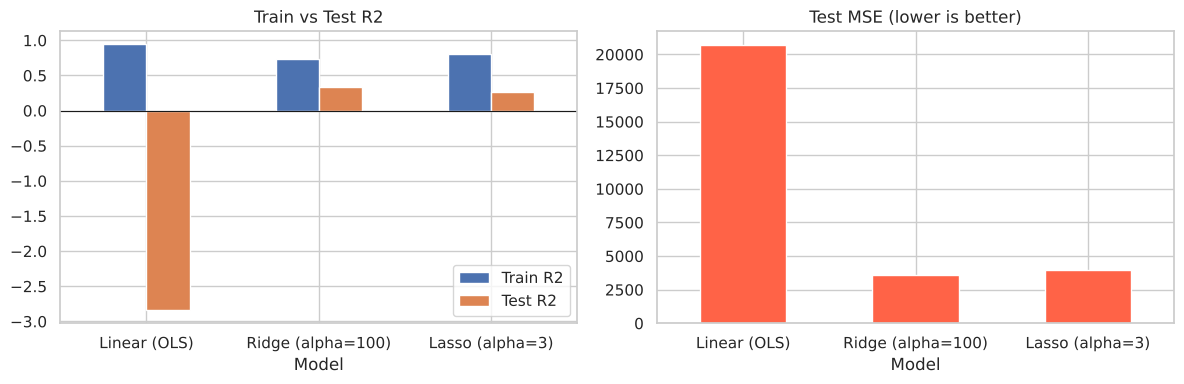

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res_b.set_index("Model")[["Train R2", "Test R2"]].plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_title("Train vs Test R2"); ax[0].axhline(0, color="k", lw=0.8)
res_b.set_index("Model")["Test MSE"].plot(kind="bar", ax=ax[1], color="tomato", rot=0)
ax[1].set_title("Test MSE (lower is better)")
plt.tight_layout(); plt.show()

**How to read these graphs:** compare the blue (train) and orange (test) bars.
- **OLS:** very high train R² (about 0.94) but a **negative** test R² (about -2.8): worse than simply predicting the mean. This large gap is **overfitting**: with 65 features and 80 samples the model memorised the training data.
- **Ridge and Lasso:** train R² is lower (they are not allowed to fit perfectly) but test R² is higher and the gap is much smaller. Regularisation traded a bit of bias for a large reduction in variance.

## Step 6: Validation curve (test error vs alpha)

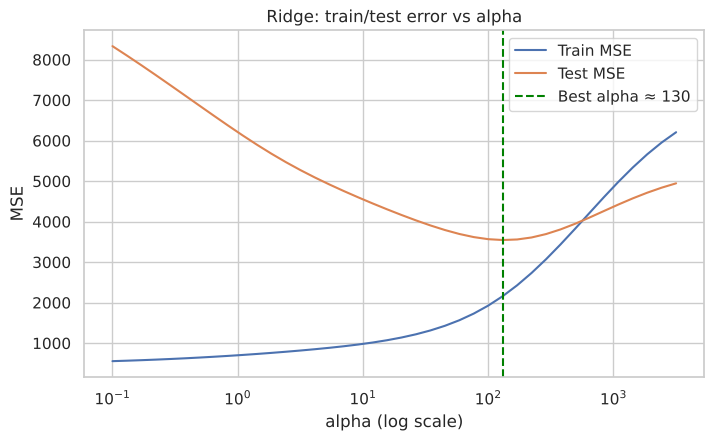

In [12]:
al = np.logspace(-1, 3.5, 40)
tr_r, te_r = [], []
for a in al:
    m = make(Ridge(alpha=a)).fit(Xs_tr, ys_tr)
    tr_r.append(mean_squared_error(ys_tr, m.predict(Xs_tr)))
    te_r.append(mean_squared_error(y_test, m.predict(X_test)))

best_a = al[int(np.argmin(te_r))]
plt.figure(figsize=(8, 4.5))
plt.plot(al, tr_r, label="Train MSE"); plt.plot(al, te_r, label="Test MSE")
plt.axvline(best_a, color="green", ls="--", label=f"Best alpha ≈ {best_a:.0f}")
plt.xscale("log"); plt.xlabel("alpha (log scale)"); plt.ylabel("MSE"); plt.legend()
plt.title("Ridge: train/test error vs alpha"); plt.show()

**How to read this:**
- **Small alpha (left):** train error is very low but test error is high: **overfitting** (high variance).
- **Large alpha (right):** both errors are high and close together: **underfitting** (high bias), because the penalty forces all coefficients near zero.
- The **minimum of the test curve (green line)** is the best alpha. This is the bias-variance trade-off controlled by alpha.

## Result / Conclusion
- **Multicollinearity:** OLS coefficients of correlated features (`s1`, `s2`) were large, opposite in sign and unstable across resamples. Ridge stabilised them; Lasso removed some features.
- **Overfitting:** with many features and few samples OLS had a big train/test gap; Ridge and Lasso reduced the gap and improved test error.
- Alpha controls the strength of regularisation, and the best value is found by cross-validation.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is regularisation and why use it?**
Adding a penalty on the size of the coefficients to the loss function. It prevents overfitting, stabilises models with multicollinearity and (Lasso) performs feature selection.

**Q2. What is Ridge regression (L2)?**
Linear regression with a penalty of alpha times the sum of squared coefficients: $\min \sum(y_i-\hat{y}_i)^2 + \alpha\sum\beta_j^2$. It shrinks coefficients but does not make them exactly zero.

**Q3. What is Lasso regression (L1)?**
Linear regression with a penalty of alpha times the sum of absolute coefficients: $\min \sum(y_i-\hat{y}_i)^2 + \alpha\sum|\beta_j|$. It can shrink some coefficients exactly to zero, so it also selects features.

**Q4. Difference between Ridge and Lasso?**
Ridge uses L2 and keeps all features with smaller weights; best when all features matter and are correlated. Lasso uses L1 and removes features; best when many features are irrelevant (sparse models).

**Q5. Why does Lasso give exact zeros but Ridge does not?**
The L1 constraint region is a diamond with corners on the axes, so the loss contours often touch at a corner where a coefficient is zero. The L2 region is a circle with no corners, so exact zeros are rare.

**Q6. What does alpha (lambda) control?**
The strength of the penalty. Alpha = 0 gives ordinary linear regression. Larger alpha means stronger shrinkage, higher bias and lower variance. Too large leads to underfitting.

**Q7. How do you choose alpha?**
By cross-validation (`RidgeCV`, `LassoCV`, `GridSearchCV`), choosing the alpha with the lowest validation error.

**Q8. What is multicollinearity?**
High correlation between independent variables, which makes coefficient estimates unreliable (large, unstable, sign-flipping). Detect it with the correlation matrix or VIF.

**Q9. How does Ridge handle multicollinearity?**
With correlated features, OLS coefficients become huge and unstable. The L2 penalty spreads weight across correlated features and stabilises the solution; it also makes $X^TX + \alpha I$ always invertible.

**Q10. How does Lasso behave with correlated features?**
It tends to pick one of them and set the others to zero, and the choice can be arbitrary and change between samples.

**Q11. What is Elastic Net?**
A combination of L1 and L2 penalties, useful when features are correlated and you also want sparsity.

**Q12. Why scale data before Ridge or Lasso?**
The penalty treats all coefficients equally, so features with large scales would be penalised unfairly. Standardising makes the penalty fair.

**Q13. Is the intercept penalised?**
No, only the feature coefficients are.

**Q14. Effect of regularisation on bias and variance?**
It increases bias slightly and decreases variance, which usually lowers test error when the model was overfitting.

**Q15. When would you not use regularisation?**
When the model already underfits, or when there are few features and plenty of data.

**Q16. Is Lasso a feature selection method?**
Yes, an embedded one, because selection happens during training.

**Q17. What is overfitting and how did you see it in this practical?**
When a model fits training data too closely and performs poorly on new data. In Part B, OLS had a high training R² but a low test R².

**Q18. What happens when alpha = 0? When alpha is very large?**
Alpha = 0 is plain OLS. A very large alpha pushes all coefficients to (nearly) zero, so the model predicts roughly the mean (underfitting).

**Q19. Does regularisation always improve test accuracy?**
No. If the model is not overfitting (as in Part A on 10 features), the improvement is small or none. It helps most with many features, few samples or collinearity.

**Q20. What is the VIF?**
Variance Inflation Factor: $1/(1-R_j^2)$, where $R_j^2$ comes from regressing feature j on the others. Values above 5 to 10 indicate problematic collinearity.

**Q21. Closed-form solution of Ridge?**
$\beta = (X^TX + \alpha I)^{-1}X^Ty$. Lasso has no closed form and is solved with coordinate descent.

**Q22. Does Ridge perform feature selection?**
No. It keeps all features.

## B. Questions about the graphs

**G1. Explain the coefficient bar plot.**
Each group of bars is one feature; the colours are the models. OLS has the largest coefficients (large with opposite signs for correlated features `s1` and `s2`). Ridge bars are smaller. Lasso has some bars exactly at zero, so those features are removed.

**G2. Explain the Ridge coefficient path.**
X-axis: alpha (log). Y-axis: coefficient values. At small alpha the coefficients equal the OLS values. As alpha grows, all coefficients shrink smoothly toward zero but never exactly reach it.

**G3. Explain the Lasso coefficient path.**
As alpha grows, coefficients hit exactly zero one at a time and stay there. The last features to reach zero are the most important ones.

**G4. What does the validation curve (error vs alpha) show?**
Train and test error versus alpha. Tiny alpha gives overfitting (low train error, high test error); huge alpha gives underfitting (both high); the minimum of the test curve is the best alpha.

**G5. What does the gap between train and test R² show?**
A large gap means overfitting. Regularisation shrinks the gap.

**G6. What does the bootstrap (s1 vs s2) scatter show?**
How much the two coefficients vary across resampled datasets. A wide tilted cloud for OLS means unstable, negatively tied estimates (multicollinearity). A tighter cloud for Ridge means regularisation stabilised them.

**G7. What does the "non-zero coefficients vs alpha" plot show?**
The number of features Lasso keeps decreases as alpha increases, until none remain.

**G8. What does the correlation heatmap show?**
Which features are strongly correlated (for example `s1` and `s2` at about 0.9), indicating multicollinearity.

## C. Code questions

**C1. What is the difference between `Ridge(alpha=10)` and `RidgeCV`?**
`Ridge` uses a fixed alpha. `RidgeCV` tries many alphas by cross-validation and keeps the best.

**C2. Why `max_iter` in Lasso?**
Lasso is solved iteratively (coordinate descent); more iterations may be needed to converge.

**C3. Why `np.logspace` for alphas?**
The effect of alpha changes over orders of magnitude, so a logarithmic grid covers the range efficiently.

**C4. Why scale inside a pipeline in Part B?**
So scaling is fitted only on the training data and applied automatically to test data.

**C5. How do you get the features Lasso kept?**
Those where `model.coef_` is not zero.